# Evaluar si recordar contextos mejora una combinación

**Pregunta:** ¿La regla fija ContextMemory mejora el MASE final medio respecto de una combinación equivalente que utiliza solamente recencia en los quince casos seleccionados?

## Objetivos

Evaluaremos una propuesta de pronóstico con una condición explícita para rechazar su beneficio supuesto. ContextMemory estima pérdidas de expertos en orígenes históricos completos y favorece contextos similares al actual. La hipótesis sostiene que la recurrencia aporta información adicional a la recencia. Ejecutaremos la regla y dos ablaciones, inspeccionaremos pesos, disponibilidad temporal y cambios de unidades, y leeremos el experimento común ya fijado. Conservaremos su resultado agregado desfavorable en lugar de modificar la configuración después de observarlo.

La literatura ya contiene combinaciones dependientes de características y ensambles dinámicos. FFORMA aprende combinaciones mediante una colección de referencia; los ensambles arbitrados estiman competencia de expertos. Aquí se evalúa una construcción específica de memoria dentro de una serie y con pocos datos. No se afirma prioridad sobre la ponderación contextual. Se investiga un mecanismo concreto y reproducible, no la existencia de un sistema de evaluación, un envoltorio de calibración o un nombre favorable para un promedio conocido.

## Preparación

Utilice el entorno aislado definido por las dependencias directas exactas siguientes. Las tres combinaciones importan los mismos expertos. El cuaderno no busca configuraciones después de observar los resultados reservados finales.

```text
pip install numpy==2.4.6
pip install scipy==1.15.3
pip install matplotlib==3.10.8
pip install statsforecast==2.0.3
pip install lightgbm==4.6.0
pip install mlforecast==1.0.31
pip install nbformat==5.11.1
pip install nbclient==0.11.0
pip install ipykernel==7.4.0
```


In [1]:
# Configure a portable lesson session; no data are downloaded.
from pathlib import Path
import sys
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in Path.cwd().parents if (p / "product.json").is_file())
sys.path.insert(0, str(root / "data-pipeline"))
from chronoscopelab.model.forecasters import seasonal_naive, ses, holt, holt_winters, theta
from chronoscopelab.model.forecasters import gaussian_quantiles
from chronoscopelab.model.context_memory import fit_context_memory
from chronoscopelab.reevaluation import metrics
from chronoscopelab.engines.statsforecast_engine import StatsforecastForecaster
from chronoscopelab.engines.lightgbm_engine import LightGBMForecaster
plt.rcParams.update({"figure.figsize": (8, 3), "figure.dpi": 95, "font.size": 10})
plt.rcParams["svg.hashsalt"] = "chronoscope-lessons"
import importlib.metadata
packages = ("numpy", "scipy", "matplotlib", "statsforecast", "lightgbm", "mlforecast",
            "nbformat", "nbclient", "ipykernel")
for package in packages:
    print(package, importlib.metadata.version(package))


numpy 2.4.6
scipy 1.15.3
matplotlib 3.10.8
statsforecast 2.0.3
lightgbm 4.6.0
mlforecast 1.0.31
nbformat 5.11.1
nbclient 0.11.0
ipykernel 7.4.0


## Datos

El caso generado seleccionado permite explicar visualmente el ajuste. El artefacto completo proporciona la comparación agregada declarada sobre quince bloques finales. Cumplen funciones distintas: un caso muestra cómo aparecen los pesos y la colección fija evalúa el criterio medio. Ambos utilizan historias y objetivos comprometidos. La configuración está registrada en el artefacto y en el dossier de investigación. Un resultado decepcionante o un éxito individual conveniente no justifican cambiar silenciosamente el núcleo, los expertos o la colección comparativa.


In [2]:
# The committed trace separates available history from the unseen final block.
trace = json.loads((root / "data/derived/TRND_seasonal/trace.json").read_text())
history = np.array(trace["history"], dtype=float)
actual = np.array(trace["actual"], dtype=float)
m, h = trace["seasonality"], trace["horizon"]
comparison = json.loads((root / "data/derived/reevaluation.json").read_text())
print("History:", len(history), "Season:", m, "Holdout:", h)


History: 168 Season: 12 Holdout: 12


## Método

En un máximo de doce orígenes históricos, el método ajusta cinco expertos: SeasonalNaive, SES, Holt, HoltWinters y Theta. Cada objetivo de entrenamiento debe terminar dentro de la historia disponible. El bloque futuro final queda excluido. Cuatro resúmenes describen pendiente normalizada, cambio de nivel, cambio de volatilidad y correlación estacional. Un núcleo gaussiano compara contextos recordados con el actual. La recencia decae con semivida fija de seis orígenes. Son configuraciones de implementación y no estimaciones elegidas a partir de errores finales.


In [3]:
# Fit the fixed context kernel using only completed targets within the history.
context_fit = fit_context_memory(history, m, h, mode="context")
print("Completed training origins:", len(context_fit.origins))
print("Latest training target ends:", max(context_fit.origins) + h)
print("Available history ends:", len(history))


Completed training origins: 12
Latest training target ends: 168
Available history ends: 168


Compare directamente el último extremo objetivo impreso con la longitud histórica disponible. Se permite igualdad: el último objetivo recordado puede terminar en la observación ya conocida más reciente. Sobrepasar ese extremo constituiría fuga. Los orígenes no equivalen a los extremos de sus objetivos, especialmente con horizontes extensos. Las pruebas ejercitan esa frontera independientemente. Aquí los extremos impresos permiten inspeccionar la restricción sin confundir observaciones futuras cargadas para evaluar con entradas efectivamente entregadas al ajuste.

RecencyMean elimina el núcleo de distancia contextual y conserva expertos, objetivos históricos completos, decaimiento temporal y transformación de pérdidas en pesos. Así permite aislar si la similitud añade valor a la estimación reciente. Comparar ContextMemory solamente con un pronóstico ingenuo no respondería esa pregunta: una mejora podría deberse a combinar expertos y no a recordar contextos. Una ablación útil retira un componente propuesto y mantiene las otras decisiones relevantes del diseño.


In [4]:
# Remove context similarity while retaining the expert set and recency rule.
recency_fit = fit_context_memory(history, m, h, mode="recency")
print("Recency weights:", np.round(recency_fit.weights, 4))


Recency weights: [0.2659 0.1239 0.0144 0.4743 0.1216]


EqualMean asigna el mismo peso a cada experto y elimina también las preferencias de competencia estimada. Sigue produciendo un pronóstico real con las mismas trayectorias actuales. Los intervalos se combinan con los mismos pesos convexos que los puntos. Cuantiles ordenados y pesos no negativos conservan el orden, pero no demuestran calibración probabilística. Promediar cuantiles marginales no suele producir los cuantiles de una distribución mezcla. Esa distinción matemática limita la interpretación de las bandas combinadas.


In [5]:
# The equal-weight ablation removes estimated loss preferences as well.
uniform_fit = fit_context_memory(history, m, h, mode="uniform")
print("Equal weights:", np.round(uniform_fit.weights, 4))


Equal weights: [0.2 0.2 0.2 0.2 0.2]


Las pérdidas locales se contraen una cuarta parte hacia la estimación de recencia antes de aplicar la transformación exponencial. Un piso uniforme de cinco por ciento mantiene positivos todos los pesos. Estos regularizadores reducen concentración cuando existen pocos contextos informativos, pero también pueden diluir un especialista útil. La primera figura asocia cada peso con su experto en el caso elegido. Explica la regla ajustada y no atribuye causalmente a un experto la responsabilidad del error final.


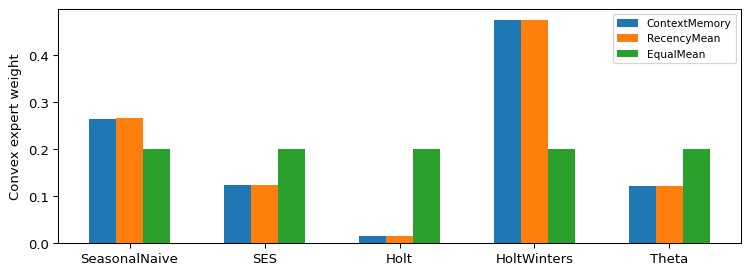

In [6]:
# Associate weights with expert identities rather than an unlabeled vector.
from chronoscopelab.model.context_memory import EXPERT_NAMES
fig, ax = plt.subplots()
x = np.arange(len(EXPERT_NAMES))
ax.bar(x - 0.2, context_fit.weights, width=0.2, label="ContextMemory")
ax.bar(x, recency_fit.weights, width=0.2, label="RecencyMean")
ax.bar(x + 0.2, uniform_fit.weights, width=0.2, label="EqualMean")
ax.set_xticks(x, EXPERT_NAMES)
ax.set(ylabel="Convex expert weight")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


El gráfico permite inspeccionar cuánto modifica realmente el núcleo la asignación por recencia. Barras semejantes indican poca influencia contextual en esta historia. Barras distintas demuestran una decisión diferente, no una decisión mejor. Sus consecuencias requieren objetivos futuros. EqualMean aporta una referencia fija para observar la concentración. Ningún experto se elimina después de conocer su error final: la comparación conserva el conjunto declarado antes de evaluar y mantiene los resultados que podrían resultar inconvenientes.

## Comparación

Evalúe las tres trayectorias recién calculadas sobre el mismo objetivo final y la misma escala estacional. Un MASE menor en este caso aporta evidencia descriptiva, pero un ejemplo favorable no resuelve la hipótesis agregada. La celda imprime los tres resultados, sin seleccionar solamente al ganador. La similitud contextual puede ayudar en un régimen y perjudicar en otro. Si la pregunta se refiere al promedio de una colección fija, deben conservarse ambos resultados individuales.


In [7]:
# Evaluate the ablations against the same target and the same history scale.
for name, fit in (("ContextMemory", context_fit), ("RecencyMean", recency_fit), ("EqualMean", uniform_fit)):
    q = fit.quantiles
    score = metrics(history, actual, q[:, 1], q[:, 0], q[:, 2], m)
    print(name, "case MASE", round(score["mase"], 4))


ContextMemory case MASE 0.5557
RecencyMean case MASE 0.5545
EqualMean case MASE 1.0389


Cambiar unidades permite comprobar estructura independientemente de la clasificación. Los resúmenes contextuales y las pérdidas normalizadas se diseñaron para mantener sus pesos ante un cambio positivo de escala y un desplazamiento común. Multiplicar por diez y añadir cien debería conservarlos salvo redondeo numérico. Esta comprobación no mide precisión futura: pregunta si una transformación que mantiene la estructura relativa de la serie altera innecesariamente la regla de combinación propuesta.


In [8]:
# Changing units should preserve the context rule's convex weights.
converted = fit_context_memory(history * 10 + 100, m, h, mode="context")
print("Maximum weight change after unit conversion:", f"{np.max(np.abs(converted.weights - context_fit.weights)):.8f}")


Maximum weight change after unit conversion: 0.00000000


## Evidencia

El criterio primario declarado es el MASE medio sobre los quince bloques finales comunes. ContextMemory debe mejorar RecencyMean para respaldar el beneficio contextual en este experimento. La figura final lee los agregados ya persistidos, incluidos casos desfavorables, sin reajustar ni seleccionar parámetros. Hay solamente un origen por serie seleccionada: no permite concluir significancia ni generalización poblacional. Sin embargo, sí permite rechazar una mejora agregada afirmada sobre esta colección concreta.


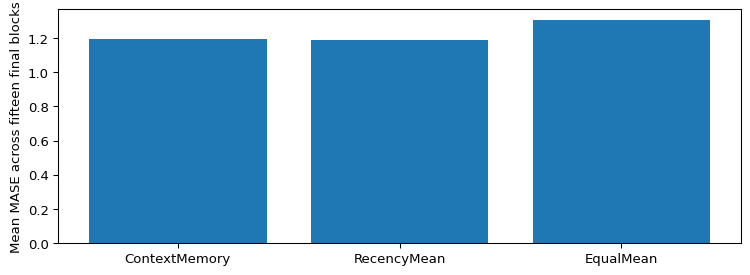

ContextMemory mean MASE 1.1921
RecencyMean mean MASE 1.1898
EqualMean mean MASE 1.3047


In [9]:
# Read the already fixed fifteen-case experiment, without tuning to its outcomes.
names = ["ContextMemory", "RecencyMean", "EqualMean"]
means = [next(row["mean_mase"] for row in comparison["summary"] if row["name"] == name) for name in names]
fig, ax = plt.subplots()
ax.bar(names, means)
ax.set(ylabel="Mean MASE across fifteen final blocks")
fig.tight_layout()
plt.show()
for name, value in zip(names, means, strict=True):
    print(name, "mean MASE", f"{value:.4f}")


Las barras muestran una diferencia pequeña entre las variantes contextual y de recencia, y una separación mayor respecto de EqualMean. Como la media contextual resulta ligeramente superior, el experimento no respalda ese componente en el criterio declarado. Redondear a dos decimales ocultaría el resultado; las cuatro cifras impresas lo conservan. Una comparación fallida sigue siendo evidencia y debe limitar la afirmación del manuscrito, en vez de provocar ajustes no declarados contra el conjunto reservado.

## Resultados

**Respuesta:** ContextMemory obtiene MASE medio 1,1921 y RecencyMean 1,1898. La regla contextual falla su criterio declarado de error medio en esta colección. EqualMean obtiene 1,3047. Estimar pérdidas recientes ayudó frente al promedio uniforme en estos casos, pero el núcleo contextual adicional no mejoró la comparación primaria. Las cifras conservan la precisión de la salida computada.

Estos valores no establecen equivalencia ni demuestran que ponderar contextos nunca pueda ayudar. Identifican un experimento fijo sin éxito. Un seguimiento debe declarar datos más amplios, varios orígenes, incertidumbre que considere dependencia y costos computacionales antes de ejecutarse. Modificar parámetros define otro experimento y no debe sobrescribir este. Los orígenes empleados para estimar pesos aportan entrenamiento, no repeticiones independientes adicionales de la evaluación final.

## Resumen

Una propuesta evaluable necesita mecanismo, ablaciones equivalentes, una frontera de información temporal y un criterio explícito de fallo. ContextMemory aporta esas piezas y recibe un resultado inicial negativo. Conserve implementación, configuraciones, predicciones individuales y agregados para permitir inspeccionar el fallo. La investigación posterior puede mejorar la regla o rechazar su premisa; ninguna alternativa permite afirmar superioridad a partir del experimento actual.

## Referencias

- Promedios por características: https://doi.org/10.1016/j.ijforecast.2019.02.011
- Ensambles dinámicos: https://doi.org/10.1007/s10994-018-05774-y
- Escalamiento: https://doi.org/10.1016/j.ijforecast.2006.03.001
- Experto Theta: https://robjhyndman.com/papers/Theta.pdf
- Experto estacional: https://otexts.com/fpp3/holt-winters.html
